In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Welcome to my Sales Data Analysis project!")
print("Libraries imported successfully.")


Welcome to my Sales Data Analysis project!
Libraries imported successfully.



# Sales Data Analysis

## Coding Samurai Data Science Internship

**Objective:** Analyze retail sales data using Python, Pandas, NumPy, and Matplotlib.

**Project level:** Beginner

**Key activities:**
- Data cleaning
- Descriptive statistics
- Product and category analysis
- Data visualization
- Business insights


In [5]:

import pandas as pd
import numpy as np

# Make the results consistent each time we run the code
np.random.seed(42)

# Product information
products = {
    "Laptop": {"category": "Electronics", "price": 55000},
    "Headphones": {"category": "Electronics", "price": 1500},
    "Keyboard": {"category": "Accessories", "price": 800},
    "Mouse": {"category": "Accessories", "price": 500},
    "Chair": {"category": "Furniture", "price": 4500},
    "Desk": {"category": "Furniture", "price": 8000},
    "Notebook": {"category": "Stationery", "price": 100},
    "Pen": {"category": "Stationery", "price": 20}
}

# Generate 200 sample orders
number_of_orders = 200

selected_products = np.random.choice(
    list(products.keys()),
    size=number_of_orders
)

sales_data = pd.DataFrame({
    "Order_ID": [
        f"ORD{i:04d}" for i in range(1, number_of_orders + 1)
    ],
    "Date": pd.to_datetime(
        np.random.choice(
            pd.date_range("2026-01-01", "2026-06-30"),
            size=number_of_orders
        )
    ),
    "Product": selected_products,
    "Quantity": np.random.randint(1, 6, size=number_of_orders),
    "Region": np.random.choice(
        ["North", "South", "East", "West"],
        size=number_of_orders
    ),
    "Payment_Method": np.random.choice(
        ["UPI", "Card", "Cash", "Net Banking"],
        size=number_of_orders
    )
})

# Add product categories and prices
sales_data["Category"] = sales_data["Product"].map(
    lambda p: products[p]["category"]
)

sales_data["Unit_Price"] = sales_data["Product"].map(
    lambda p: products[p]["price"]
)

# Calculate sales amount
sales_data["Sales"] = (
    sales_data["Quantity"] * sales_data["Unit_Price"]
)

print("Sales dataset created successfully!")
print("Number of rows and columns:", sales_data.shape)


Sales dataset created successfully!
Number of rows and columns: (200, 9)


In [6]:

# Display the first five records
display(sales_data.head())

# Display the column names
print("Column names:")
print(sales_data.columns.tolist())

# Display basic information about the dataset
sales_data.info()


,Order_ID,Date,Product,Quantity,Region,Payment_Method,Category,Unit_Price,Sales
0,ORD0001,2026-03-04,Notebook,5,North,Card,Stationery,100,500
1,ORD0002,2026-04-06,Mouse,5,North,Card,Accessories,500,2500
2,ORD0003,2026-02-21,Chair,1,East,Cash,Furniture,4500,4500
3,ORD0004,2026-04-06,Notebook,3,West,Net Banking,Stationery,100,300
4,ORD0005,2026-05-12,Keyboard,2,North,UPI,Accessories,800,1600


Column names:
['Order_ID', 'Date', 'Product', 'Quantity', 'Region', 'Payment_Method', 'Category', 'Unit_Price', 'Sales']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        200 non-null    object        
 1   Date            200 non-null    datetime64[ns]
 2   Product         200 non-null    object        
 3   Quantity        200 non-null    int64         
 4   Region          200 non-null    object        
 5   Payment_Method  200 non-null    object        
 6   Category        200 non-null    object        
 7   Unit_Price      200 non-null    int64         
 8   Sales           200 non-null    int64         
dtypes: datetime64[ns](1), int64(3), object(5)
memory usage: 14.2+ KB


In [7]:

# 1. Check for missing values
print("Missing values in each column:")
print(sales_data.isnull().sum())

# 2. Check for duplicate rows
print("\nNumber of duplicate rows:")
print(sales_data.duplicated().sum())

# 3. Calculate basic statistics
print("\nBasic statistical summary:")
display(sales_data.describe())

# 4. Check the unique products
print("\nProducts available:")
print(sales_data["Product"].unique())

# 5. Check the number of orders per region
print("\nOrders by region:")
print(sales_data["Region"].value_counts())


Missing values in each column:
Order_ID          0
Date              0
Product           0
Quantity          0
Region            0
Payment_Method    0
Category          0
Unit_Price        0
Sales             0
dtype: int64

Number of duplicate rows:
0

Basic statistical summary:


,Date,Quantity,Unit_Price,Sales
count,200,200.000000,200.000000,200.000000
mean,2026-04-06 21:57:36,2.980000,8054.900000,25577.800000
min,2026-01-02 00:00:00,1.000000,20.000000,20.000000
25%,2026-02-20 18:00:00,2.000000,100.000000,500.000000
50%,2026-04-13 12:00:00,3.000000,800.000000,2500.000000
75%,2026-05-20 12:00:00,4.000000,4500.000000,13500.000000
max,2026-06-30 00:00:00,5.000000,55000.000000,275000.000000
std,NaN,1.452636,17143.681432,61417.547221



Products available:
['Notebook' 'Mouse' 'Chair' 'Keyboard' 'Pen' 'Headphones' 'Desk' 'Laptop']

Orders by region:
Region
North    61
West     52
East     45
South    42
Name: count, dtype: int64


In [8]:

# Create a copy for cleaning practice
sales_data_dirty = sales_data.copy()

# Introduce two missing values
sales_data_dirty.loc[5, "Region"] = np.nan
sales_data_dirty.loc[12, "Quantity"] = np.nan

# Add a duplicate record
sales_data_dirty = pd.concat(
    [sales_data_dirty, sales_data_dirty.iloc[[0]]],
    ignore_index=True
)

# Check the data-quality problems
print("Dataset shape:", sales_data_dirty.shape)

print("\nMissing values:")
print(sales_data_dirty.isnull().sum())

print("\nDuplicate rows:")
print(sales_data_dirty.duplicated().sum())


Dataset shape: (201, 9)

Missing values:
Order_ID          0
Date              0
Product           0
Quantity          1
Region            1
Payment_Method    0
Category          0
Unit_Price        0
Sales             0
dtype: int64

Duplicate rows:
1


In [9]:

# Remove duplicate records
cleaned_sales = sales_data_dirty.drop_duplicates().copy()

# Fill the missing region with "Unknown"
cleaned_sales["Region"] = cleaned_sales["Region"].fillna("Unknown")

# Fill missing quantity using the median
cleaned_sales["Quantity"] = cleaned_sales["Quantity"].fillna(
    cleaned_sales["Quantity"].median()
)

# Recalculate sales after cleaning quantity
cleaned_sales["Sales"] = (
    cleaned_sales["Quantity"] * cleaned_sales["Unit_Price"]
)

# Verify the cleaned data
print("Cleaned dataset shape:", cleaned_sales.shape)

print("\nMissing values after cleaning:")
print(cleaned_sales.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(cleaned_sales.duplicated().sum())


Cleaned dataset shape: (200, 9)

Missing values after cleaning:
Order_ID          0
Date              0
Product           0
Quantity          0
Region            0
Payment_Method    0
Category          0
Unit_Price        0
Sales             0
dtype: int64

Duplicate rows after cleaning:
0


In [10]:

# Calculate key sales metrics

total_revenue = cleaned_sales["Sales"].sum()

total_orders = cleaned_sales["Order_ID"].nunique()

total_units_sold = cleaned_sales["Quantity"].sum()

average_order_value = (
    cleaned_sales.groupby("Order_ID")["Sales"].sum().mean()
)

print("SALES PERFORMANCE SUMMARY")
print("-" * 35)
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Total Units Sold: {total_units_sold:,.0f}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")


SALES PERFORMANCE SUMMARY
-----------------------------------
Total Revenue: ₹5,116,360.00
Total Orders: 200
Total Units Sold: 597
Average Order Value: ₹25,581.80


In [11]:

product_summary = (
    cleaned_sales.groupby("Product")
    .agg(
        Units_Sold=("Quantity", "sum"),
        Total_Revenue=("Sales", "sum"),
        Number_of_Orders=("Order_ID", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
)

display(product_summary)


,Units_Sold,Total_Revenue,Number_of_Orders
Product,,,
Laptop,74.0,4070000.0,23
Desk,64.0,512000.0,21
Chair,69.0,310500.0,23
Headphones,80.0,120000.0,25
Keyboard,61.0,48800.0,23
Mouse,89.0,44500.0,30
Notebook,92.0,9200.0,31
Pen,68.0,1360.0,24


In [12]:

category_summary = (
    cleaned_sales.groupby("Category")
    .agg(
        Total_Revenue=("Sales", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
)

display(category_summary)


,Total_Revenue,Units_Sold
Category,,
Electronics,4190000.0,154.0
Furniture,822500.0,133.0
Accessories,93300.0,150.0
Stationery,10560.0,160.0


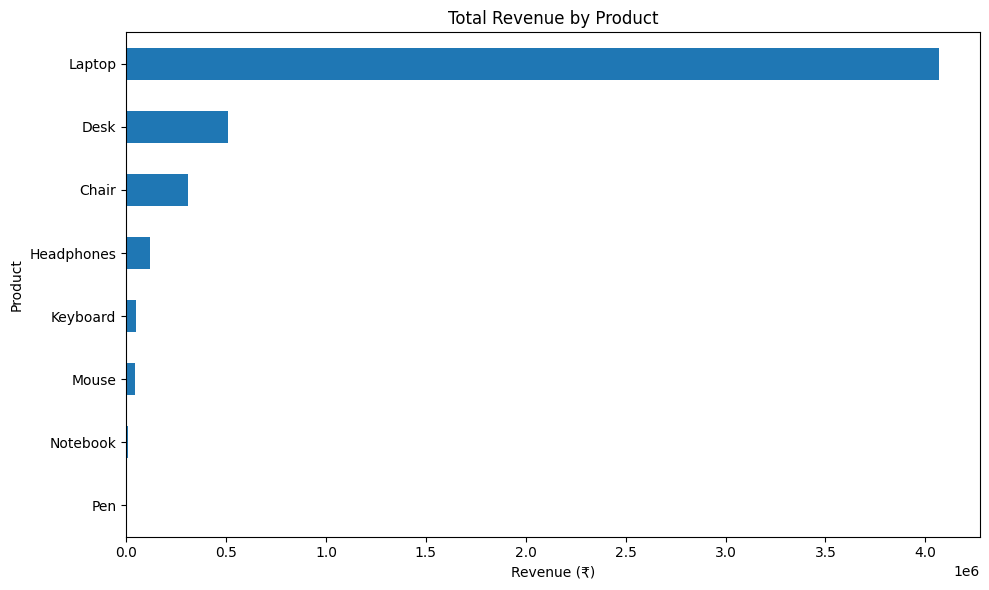

In [14]:

import matplotlib.pyplot as plt

# Sort products from lowest to highest revenue for plotting
product_revenue = product_summary["Total_Revenue"].sort_values()

# Create the chart
plt.figure(figsize=(10, 6))
product_revenue.plot(kind="barh")

plt.title("Total Revenue by Product")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


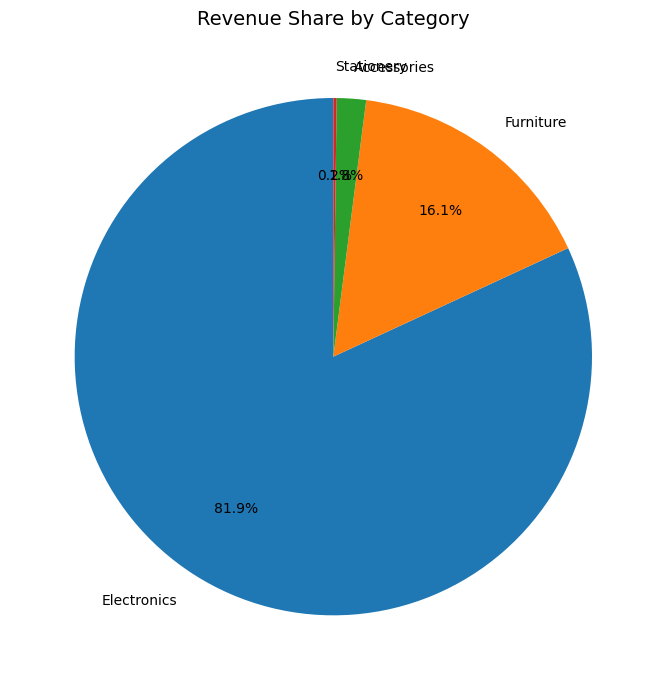

In [17]:


category_revenue = category_summary["Total_Revenue"].sort_values(
    ascending=False
)

plt.figure(figsize=(9, 7))

plt.pie(
    category_revenue,
    labels=category_revenue.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.7,
    labeldistance=1.12,
    textprops={"fontsize": 10}
)

plt.title("Revenue Share by Category", fontsize=14)
plt.tight_layout()
plt.show()


# Project Findings and Conclusion

## Key Findings

1. The dataset contains 200 simulated retail orders.
2. Total revenue was ₹51,16,360, with 597 units sold.
3. Laptop was the highest-revenue product, generating ₹40,70,000.
4. Electronics was the highest-revenue category, contributing approximately 81.9% of total revenue.
5. Notebook had the highest unit sales among individual products, with 92 units.
6. Monthly revenue peaked in April 2026 and was lowest in June 2026.

## Conclusion

This project demonstrates how Python can be used to clean data, calculate sales metrics, compare product performance, and visualize business trends. The analysis highlights differences between revenue and unit sales and demonstrates how charts can help communicate findings.

The dataset is simulated for educational purposes. The results should not be interpreted as actual retail business performance.

## Tools Used

Python, Pandas, NumPy, Matplotlib, and Google Colab.

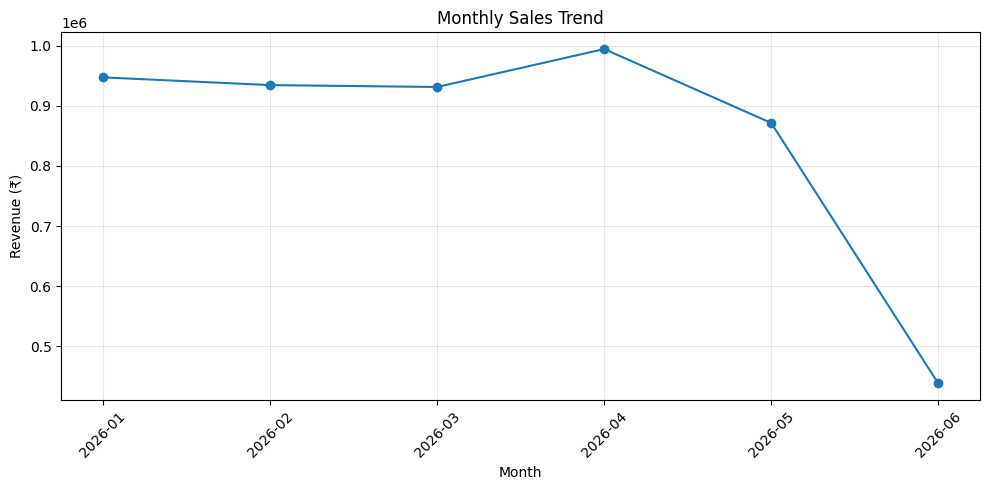

In [16]:

cleaned_sales["Month"] = (
    cleaned_sales["Date"].dt.to_period("M").astype(str)
)

monthly_sales = (
    cleaned_sales.groupby("Month")["Sales"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(10, 5))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
